# 🚗 Demo & Đánh Giá Các Module Phát Hiện Làn Đường (CPV301)

Notebook này thực thi và so sánh trực quan các module trong dự án:
1. **Tiền xử lý ảnh (`ImagePreprocessor`)**: Grayscale, CLAHE, Canny Edge, ROI Mask, Morphological Closing.
2. **Hough Transform (`HoughLaneDetector`)**: Phát hiện làn đường cổ điển bằng `cv2.HoughLinesP`.
3. **LaneNet (`LaneNetDetector`)**: Phân đoạn nhị phân + gom cụm thực thể DBSCAN.
4. **Giải pháp đề xuất (`YOLOLaneDetector` / Segmentation + `SplineFitter`)**: Nội suy đường cong B-Spline bậc 3 xử lý mượt các đoạn đường cong.
5. **Xử lý Video (`PipelineBuilder`) & Đánh giá hiệu năng (`benchmark_detector_on_frames`)**.


In [1]:
import sys
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src import (
    RAW_DATA_DIR,
    OUTPUT_DATA_DIR,
    ImagePreprocessor,
    HoughLaneDetector,
    LaneNetDetector,
    SplineFitter,
    LaneDetector,
    PipelineBuilder,
    benchmark_detector_on_frames,
)

print("Đã nạp thành công toàn bộ các module từ gói src!")


Đã nạp thành công toàn bộ các module từ gói src!


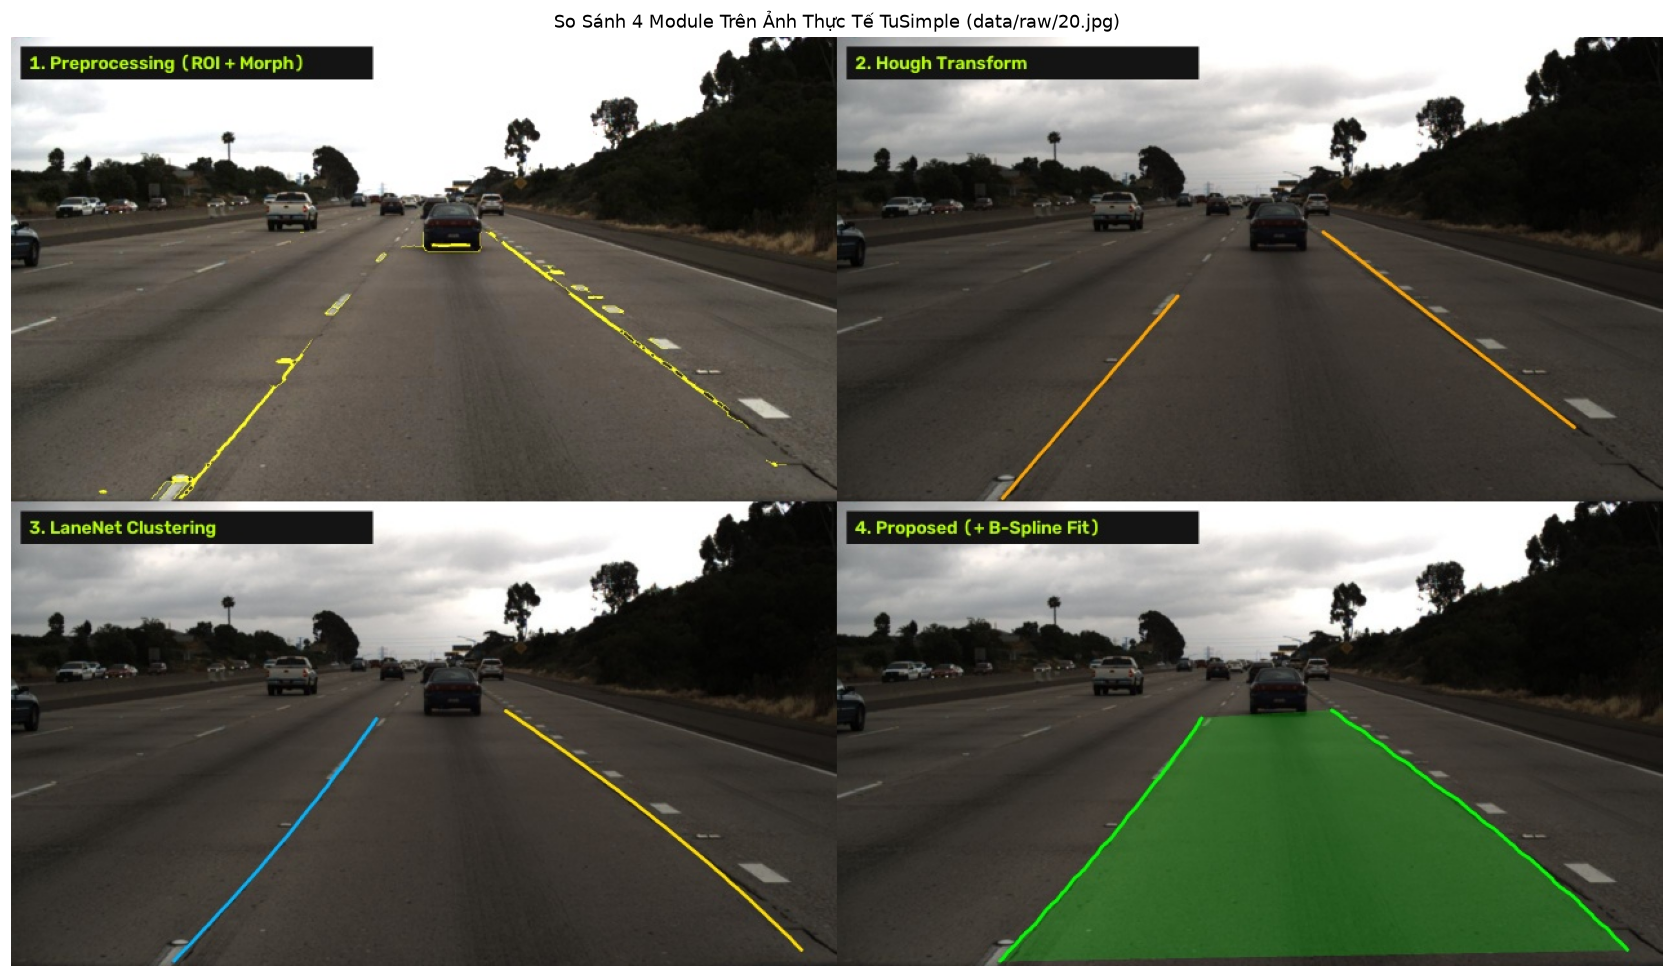

In [2]:
# 1. Chạy so sánh 4 bước/module trên ảnh thực tế TuSimple (data/raw/20.jpg)
from model.demo import run_demo_comparison

report_real = run_demo_comparison()
grid_img = cv2.imread(str(OUTPUT_DATA_DIR / "comparison_grid.jpg"))

plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(grid_img, cv2.COLOR_BGR2RGB))
plt.title("So Sánh 4 Module Trên Ảnh Thực Tế TuSimple (data/raw/20.jpg)")
plt.axis("off")
plt.tight_layout()
plt.show()


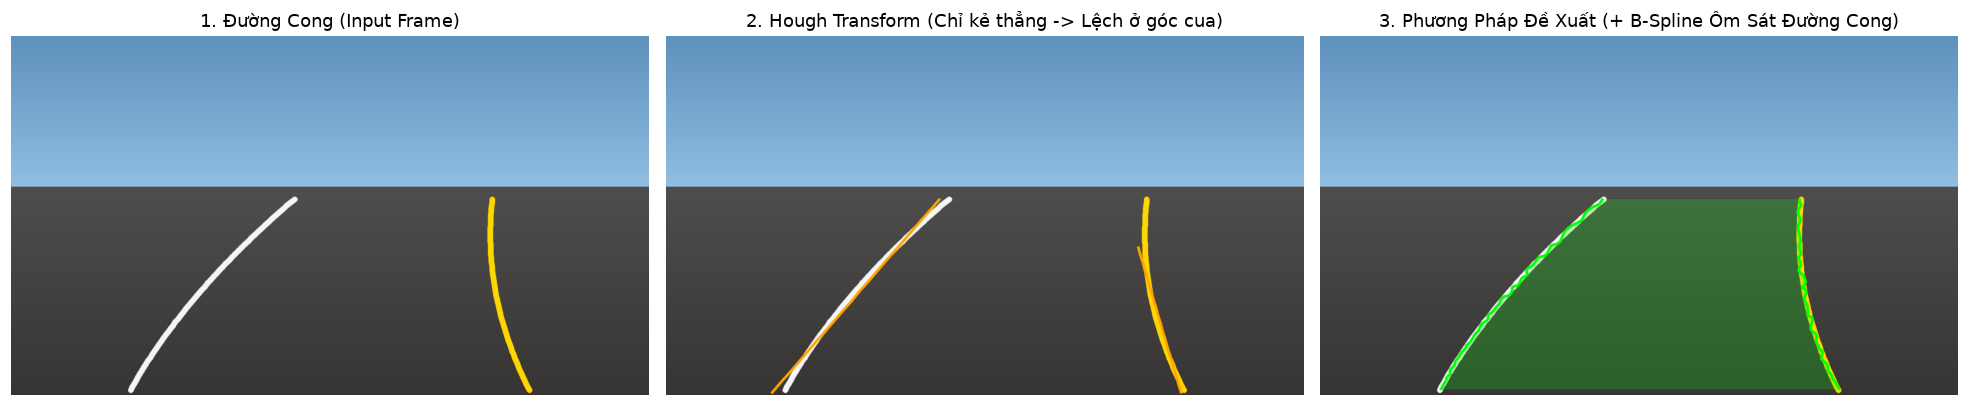

 BẢNG ĐÁNH GIÁ HIỆU NĂNG TRÊN ĐOẠN ĐƯỜNG CONG (TuSimple Metrics)
Phương pháp                  | Accuracy   | FP       | FN       | FPS     
---------------------------------------------------------------------
1. Hough Transform           | 0.8667     | 0.0000   | 0.0000   | 87.54   
2. LaneNet Clustering        | 0.8833     | 0.0000   | 0.0000   | 20.82   
3. Proposed (YOLO+Spline)    | 1.0000     | 0.0000   | 0.0000   | 569.77  


In [3]:
# 2. Kiểm chứng ưu thế của B-Spline Fitting so với Hough Transform trên đoạn đường cong
curved_frame = cv2.imread(str(RAW_DATA_DIR / "curved_road.jpg"))

pre = ImagePreprocessor(use_clahe=True, blur_ksize=5)
hough_det = HoughLaneDetector(preprocessor=pre, min_line_length=25, threshold=20)
lanenet_det = LaneNetDetector(preprocessor=pre, min_samples=12)
spline_fitter = SplineFitter(spline_order=3, smoothing=2.0, num_points=100)

_, hough_masks_c = hough_det.detect(curved_frame)
hough_vis_c = hough_det.draw_lanes(curved_frame, hough_masks_c)

_, lanenet_masks_c = lanenet_det.detect(curved_frame)
proposed_vis_c = spline_fitter.fit_and_draw(curved_frame, lanenet_masks_c)
fitted_c = spline_fitter.fit_multiple_lanes(lanenet_masks_c)
if len(fitted_c) >= 2:
    proposed_vis_c = spline_fitter.draw_lane_area(proposed_vis_c, fitted_c[0], fitted_c[1], alpha=0.22)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
axes[0].imshow(cv2.cvtColor(curved_frame, cv2.COLOR_BGR2RGB))
axes[0].set_title("1. Đường Cong (Input Frame)")
axes[1].imshow(cv2.cvtColor(hough_vis_c, cv2.COLOR_BGR2RGB))
axes[1].set_title("2. Hough Transform (Chỉ kẻ thẳng -> Lệch ở góc cua)")
axes[2].imshow(cv2.cvtColor(proposed_vis_c, cv2.COLOR_BGR2RGB))
axes[2].set_title("3. Phương Pháp Đề Xuất (+ B-Spline Ôm Sát Đường Cong)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [4]:
# 3. Chạy PipelineBuilder xử lý Video (Xuất ra data/output/output_hough.mp4 & output_proposed.mp4)
pipe_hough = PipelineBuilder(detector=hough_det, spline_fitter=None)
pipe_hough.process_video("test_driving.mp4", "output_hough.mp4")

pipe_proposed = PipelineBuilder(detector=lanenet_det, spline_fitter=spline_fitter)
pipe_proposed.process_video("test_driving.mp4", "output_proposed.mp4")


Starting pipeline processing for test_driving.mp4...
Processed 30 frames...
Processing complete! Saved to C:\Users\lehuy\OneDrive\Desktop\project_cpv\CPV301\data\output\output_hough.mp4
Starting pipeline processing for test_driving.mp4...
Processed 30 frames...
Processing complete! Saved to C:\Users\lehuy\OneDrive\Desktop\project_cpv\CPV301\data\output\output_proposed.mp4
